# Book Recommender System
Name : Shivam Zhar | Roll No: LCS2023024

In [ ]:
%pip -q install pandas numpy scipy scikit-learn pyarrow matplotlib requests
import sys, platform, importlib.metadata
print('Python:', platform.python_version())
print({p: importlib.metadata.version(p) for p in ['pandas','numpy','scipy','scikit-learn','pyarrow','matplotlib']})

Note: you may need to restart the kernel to use updated packages.
Python: 3.9.13
{'pandas': '2.0.3', 'numpy': '1.24.3', 'scipy': '1.13.1', 'scikit-learn': '1.6.1', 'pyarrow': '21.0.0', 'matplotlib': '3.9.4'}


In [ ]:
from pathlib import Path
import csv, zipfile, hashlib, shutil, json
from datetime import datetime, timezone
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix, save_npz, load_npz
from sklearn.neighbors import NearestNeighbors
from IPython.display import display, Markdown

ROOT = Path('book_lake')
for layer in ['raw', 'bronze', 'silver', 'gold']:
    (ROOT / layer).mkdir(parents=True, exist_ok=True)
URL = 'https://cdn.freecodecamp.org/project-data/books/book-crossings.zip'
archive = ROOT / 'raw/book-crossings.zip'
if not archive.exists():
    response = requests.get(URL, timeout=180)
    response.raise_for_status()
    archive.write_bytes(response.content)
source_hash = hashlib.sha256(archive.read_bytes()).hexdigest()
files = {'users': 'BX-Users.csv', 'books': 'BX-Books.csv', 'ratings': 'BX-Book-Ratings.csv'}
with zipfile.ZipFile(archive) as z:
    for filename in files.values():
        member = next(n for n in z.namelist() if Path(n).name == filename)
        (ROOT / 'raw' / filename).write_bytes(z.read(member))
timestamp = pd.Timestamp.now(tz='UTC')
for name, filename in files.items():
    df = pd.read_csv(ROOT / 'raw' / filename, sep=';', encoding='latin-1',
                     escapechar=chr(92), dtype='string', keep_default_na=False)
    df['ingestion_timestamp'] = timestamp
    df.to_parquet(ROOT / 'bronze' / (name + '.parquet'), index=False)
    print(name, df.shape)
shutil.copy2(archive, ROOT / 'bronze/book-crossings.zip')
manifest = {'url': URL, 'sha256': source_hash, 'ingested_at': str(timestamp)}
(ROOT / 'bronze/manifest.json').write_text(json.dumps(manifest, indent=2))
print('Source SHA-256:', source_hash)

users (278858, 4)
books (271379, 9)
ratings (1149780, 4)
Source SHA-256: adc7b47afb47c8e29e5f0b70a9816569b3367c5588064ba7a916f16e3ef5d060


Users shape: (278858, 4) duplicate rows: 0
Books shape: (271379, 9) duplicate rows: 0
Ratings shape: (1149780, 4) duplicate rows: 0
Recorded density=0.00136261%; sparsity=99.99863739%; explicit density=0.00050723%
Out[3]: 1412


,dtype,missing
User-ID,string,0
Location,string,0
Age,string,110762
ingestion_timestamp,"datetime64[ns, UTC]",0


,dtype,missing
ISBN,string,0
Book-Title,string,0
Book-Author,string,0
Year-Of-Publication,string,0
Publisher,string,0
Image-URL-S,string,0
Image-URL-M,string,0
Image-URL-L,string,0
ingestion_timestamp,"datetime64[ns, UTC]",0


,dtype,missing
User-ID,string,0
ISBN,string,0
Book-Rating,string,0
ingestion_timestamp,"datetime64[ns, UTC]",0


,count
Book-Rating,
0,716109
1,1770
2,2759
3,5996
4,8904
5,50974
6,36924
7,76457
8,103736


,age,publication_year
count,168096.0,271379.0
mean,34.751434,1959.75605
std,14.428097,258.011363
min,0.0,0.0
25%,24.0,1989.0
50%,32.0,1995.0
75%,44.0,2000.0
max,244.0,2050.0


,ratings_per_active_user,ratings_per_active_book
count,105283.000000,340556.000000
mean,10.920851,3.376185
std,90.562825,12.436252
min,1.000000,1.000000
25%,1.000000,1.000000
50%,1.000000,1.000000
75%,4.000000,2.000000
max,13602.000000,2502.000000


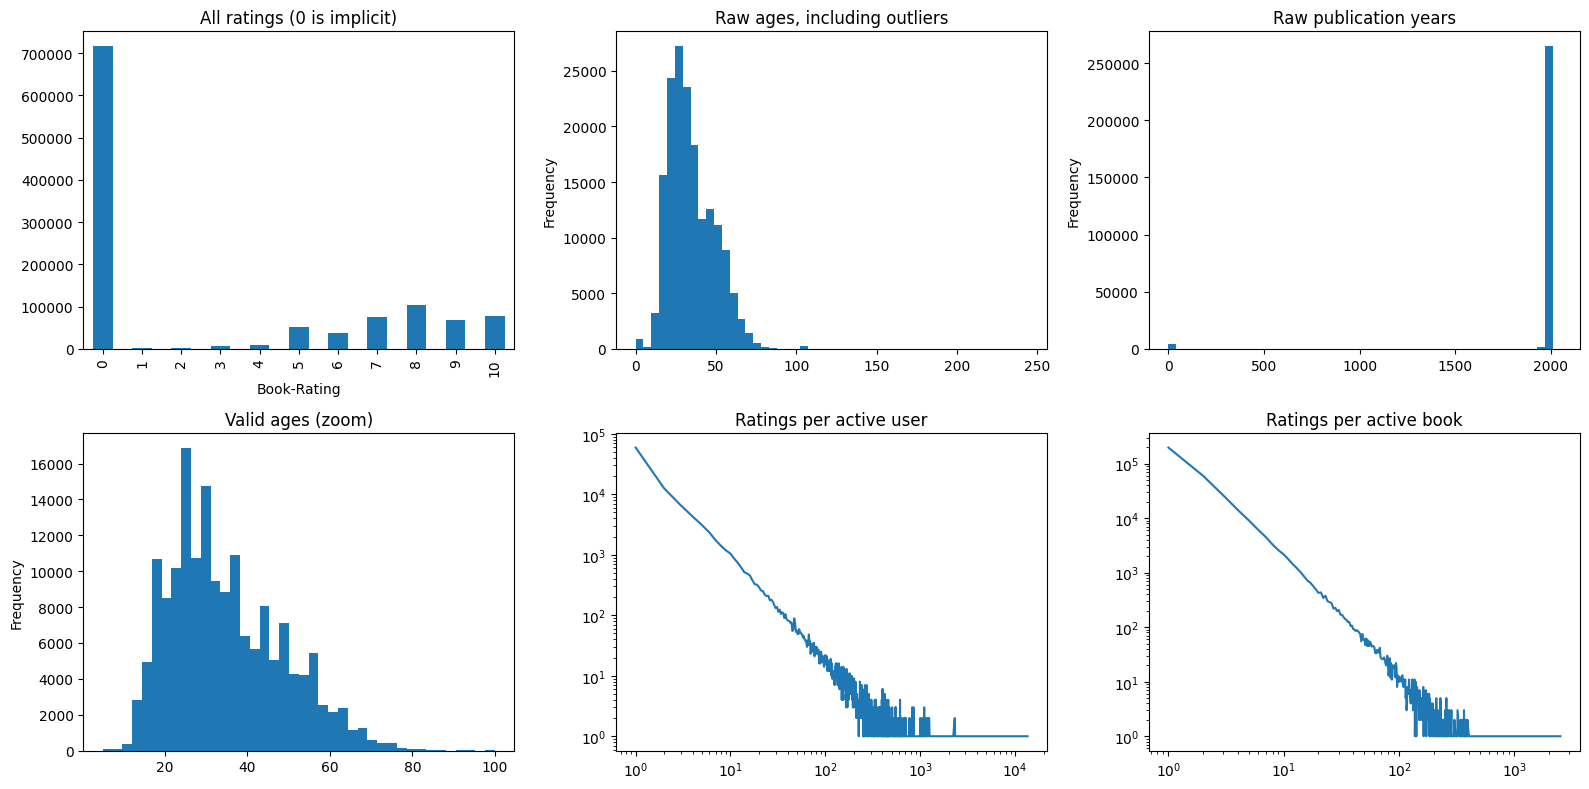

### EDA observations from this execution

- **Users:** shape (278858, 4); source fields are strings plus a UTC timestamp; missing values: Age: 110,762. Silver converts numeric fields, removes duplicates and cleans text.
- **Books:** shape (271379, 9); source fields are strings plus a UTC timestamp; missing values: none. Silver converts numeric fields, removes duplicates and cleans text.
- **Ratings:** shape (1149780, 4); source fields are strings plus a UTC timestamp; missing values: none. Silver converts numeric fields, removes duplicates and cleans text.
- **Ratings:** 716,109 zeros (62.28%); Silver keeps only explicit ratings 1–10.
- **Ages:** 110,762 nonnumeric/missing and 1,248 outside 5–100; range 0–244. Silver nulls invalid ages and fills with the valid-age median.
- **Years:** 4,619 zero, 11 future and 0 nonnumeric years; range 0–2050. Silver sets invalid years to null.
- **Frequency:** 92,186/105,283 active users and 322,237/340,556 active books have fewer than 10 raw interactions (medians 1 and 1). Silver requires 10 explicit ratings per user and book to reduce weak similarity evidence; iterative filtering enforces both thresholds, with a popularity/coverage tradeoff.
- **Sparsity:** 1,031,175/75,676,205,182 valid catalog pairs are recorded: density 0.00136261%, sparsity 99.99863739%; explicit density 0.00050723%. Gold uses sparse storage; zero ratings are not model observations.

In [ ]:
u, b, r = [pd.read_parquet(ROOT / 'bronze' / (name + '.parquet')) for name in ['users','books','ratings']]
def missing(s):
    return s.isna() | s.astype('string').str.strip().str.lower().isin(['', 'null', 'nan'])
summaries = {}
for name, frame in [('Users',u),('Books',b),('Ratings',r)]:
    summary = pd.DataFrame({'dtype':frame.dtypes.astype(str), 'missing':frame.apply(lambda s: int(missing(s).sum()))})
    summaries[name] = summary
    print(name, 'shape:', frame.shape, 'duplicate rows:', frame.drop(columns='ingestion_timestamp').duplicated().sum())
    display(summary)
rv = pd.to_numeric(r['Book-Rating'], errors='coerce')
ages = pd.to_numeric(u['Age'], errors='coerce')
years = pd.to_numeric(b['Year-Of-Publication'], errors='coerce')
CURRENT_YEAR = datetime.now(timezone.utc).year
rc = rv.value_counts().sort_index()
display(rc.rename('count').to_frame())
display(pd.DataFrame({'age':ages.describe(), 'publication_year':years.describe()}))
per_user = r.groupby('User-ID').size()
per_book = r.groupby('ISBN').size()
display(pd.DataFrame({'ratings_per_active_user':per_user.describe(), 'ratings_per_active_book':per_book.describe()}))
matched = r[r['User-ID'].isin(u['User-ID']) & r['ISBN'].isin(b['ISBN'])]
pairs = matched[['User-ID','ISBN']].drop_duplicates()
possible = u['User-ID'].nunique() * b['ISBN'].nunique()
density = 100 * len(pairs) / possible
explicit_pairs = matched[pd.to_numeric(matched['Book-Rating']).between(1,10)][['User-ID','ISBN']].drop_duplicates()
explicit_density = 100 * len(explicit_pairs) / possible
print(f'Recorded density={density:.8f}%; sparsity={100-density:.8f}%; explicit density={explicit_density:.8f}%')
fig, axes = plt.subplots(2,3,figsize=(16,8))
rc.plot.bar(ax=axes[0,0], title='All ratings (0 is implicit)')
ages.dropna().plot.hist(bins=50,ax=axes[0,1],title='Raw ages, including outliers')
years.dropna().plot.hist(bins=50,ax=axes[0,2],title='Raw publication years')
ages[ages.between(5,100)].plot.hist(bins=40,ax=axes[1,0],title='Valid ages (zoom)')
for values, ax, label in [(per_user,axes[1,1],'Ratings per active user'),(per_book,axes[1,2],'Ratings per active book')]:
    values.value_counts().sort_index().plot(ax=ax,logx=True,logy=True,title=label)
plt.tight_layout(); plt.show()
observations = []
for name, frame in [('Users',u),('Books',b),('Ratings',r)]:
    counts = summaries[name]['missing']
    detail = ', '.join(f'{k}: {v:,}' for k,v in counts.items() if v) or 'none'
    observations.append(f'- **{name}:** shape {frame.shape}; source fields are strings plus a UTC timestamp; missing values: {detail}. Silver converts numeric fields, removes duplicates and cleans text.')
observations += [
 f'- **Ratings:** {(rv==0).sum():,} zeros ({(rv==0).mean():.2%}); Silver keeps only explicit ratings 1–10.',
 f'- **Ages:** {ages.isna().sum():,} nonnumeric/missing and {(~ages.between(5,100) & ages.notna()).sum():,} outside 5–100; range {ages.min()}–{ages.max()}. Silver nulls invalid ages and fills with the valid-age median.',
 f'- **Years:** {(years==0).sum():,} zero, {(years>CURRENT_YEAR).sum():,} future and {years.isna().sum():,} nonnumeric years; range {years.min()}–{years.max()}. Silver sets invalid years to null.',
 f'- **Frequency:** {(per_user<10).sum():,}/{len(per_user):,} active users and {(per_book<10).sum():,}/{len(per_book):,} active books have fewer than 10 raw interactions (medians {per_user.median():g} and {per_book.median():g}). Silver requires 10 explicit ratings per user and book to reduce weak similarity evidence; iterative filtering enforces both thresholds, with a popularity/coverage tradeoff.',
 f'- **Sparsity:** {len(pairs):,}/{possible:,} valid catalog pairs are recorded: density {density:.8f}%, sparsity {100-density:.8f}%; explicit density {explicit_density:.8f}%. Gold uses sparse storage; zero ratings are not model observations.'
]
eda_markdown = '### EDA observations from this execution\n\n' + '\n'.join(observations)
display(Markdown(eda_markdown))
(ROOT / 'eda_observations.md').write_text(eda_markdown, encoding='utf-8')

In [ ]:
def prepare(frame):
    result = frame.drop(columns='ingestion_timestamp').drop_duplicates().copy()
    result.columns = result.columns.str.lower().str.replace('-', '_')
    return result
us, bs, rs = map(prepare, [u,b,r])
def clean_text(s):
    s = s.astype('string').str.strip().str.replace(r'\s+', ' ', regex=True).str.lower()
    return s.mask(missing(s))
us['user_id'] = pd.to_numeric(us['user_id'], errors='coerce').astype('Int64')
us = us.dropna(subset=['user_id']).drop_duplicates('user_id').copy()
age = pd.to_numeric(us['age'], errors='coerce')
age = age.where(age.between(5,100))
median_age = age.median()
us['age'] = age.fillna(median_age)
parts = clean_text(us['location']).str.rsplit(',', n=2, expand=True).reindex(columns=[0,1,2])
parts.columns = ['city','state','country']
for col in parts: us[col] = clean_text(parts[col])
us = us.drop(columns='location')
bs['isbn'] = bs['isbn'].str.strip().str.upper()
bs = bs[~missing(bs['isbn'])].copy()
for col in ['book_title','book_author','publisher']: bs[col] = clean_text(bs[col])
bs = bs.dropna(subset=['book_title']).drop_duplicates('isbn').copy()
bs['book_author'] = bs['book_author'].fillna('unknown')
y = pd.to_numeric(bs['year_of_publication'],errors='coerce')
bs['year_of_publication'] = y.where(y.between(1,CURRENT_YEAR))
bs = bs.drop(columns=[c for c in bs if c.startswith('image_url')])
rs['user_id'] = pd.to_numeric(rs['user_id'],errors='coerce').astype('Int64')
rs['isbn'] = rs['isbn'].str.strip().str.upper()
rs['book_rating'] = pd.to_numeric(rs['book_rating'],errors='coerce')
rs = rs[rs['user_id'].isin(us['user_id']) & rs['isbn'].isin(bs['isbn'])].copy()
seen = rs[['user_id','isbn']].drop_duplicates()
rs = rs[rs['book_rating'].between(1,10)].drop_duplicates()
rs = rs.groupby(['user_id','isbn'],as_index=False)['book_rating'].mean()
before = len(rs)
MIN_RATINGS = 10
history = []
while True:
    old = len(rs)
    uc, bc = rs['user_id'].value_counts(), rs['isbn'].value_counts()
    rs = rs[rs['user_id'].isin(uc[uc>=MIN_RATINGS].index) & rs['isbn'].isin(bc[bc>=MIN_RATINGS].index)].copy()
    history.append({'iteration':len(history)+1,'ratings':len(rs),'users':rs.user_id.nunique(),'books':rs.isbn.nunique()})
    if len(rs)==old: break
assert len(rs)>0
us = us[us.user_id.isin(rs.user_id)].copy()
bs = bs[bs.isbn.isin(rs.isbn)].copy()
seen = seen[seen.user_id.isin(us.user_id) & seen.isbn.isin(bs.isbn)].copy()
display(pd.DataFrame(history))
print(f'Median age: {median_age}; retained {len(rs):,}/{before:,} explicit ratings ({len(rs)/before:.2%})')
for name, frame in [('users',us),('books',bs),('ratings',rs),('seen_interactions',seen)]:
    frame.to_parquet(ROOT / 'silver' / (name+'.parquet'),index=False)
    print(name, frame.shape)

Median age: 32.0; retained 41,469/383,853 explicit ratings (10.80%)
users (1820, 5)
books (2030, 5)
ratings (41469, 3)
seen_interactions (106767, 2)


,iteration,ratings,users,books
0,1,87233,6319,5440
1,2,57938,2655,3277
2,3,48369,2220,2435
3,4,44679,1965,2250
4,5,43043,1896,2131
5,6,42204,1854,2078
6,7,41775,1835,2049
7,8,41604,1824,2041
8,9,41523,1823,2033
9,10,41496,1821,2032


In [ ]:
us, bs, rs, seen = [pd.read_parquet(ROOT / 'silver' / (n+'.parquet')) for n in ['users','books','ratings','seen_interactions']]
user_ids = np.sort(us.user_id.astype('int64').unique())
book_ids = np.sort(bs.isbn.unique().astype(str))
user_index = pd.DataFrame({'user_index':range(len(user_ids)), 'user_id':user_ids})
book_index = pd.DataFrame({'book_index':range(len(book_ids)), 'isbn':book_ids})
lookup = book_index.merge(bs[['isbn','book_title','book_author']],on='isbn',validate='one_to_one').sort_values('book_index')
ui = pd.Index(user_ids).get_indexer(rs.user_id)
bi = pd.Index(book_ids).get_indexer(rs.isbn)
matrix = csr_matrix((rs.book_rating.to_numpy(dtype=np.float32),(bi,ui)),shape=(len(book_ids),len(user_ids)))
save_npz(ROOT / 'gold/book_user_ratings.npz',matrix)
for name, frame in [('user_index',user_index),('book_lookup',lookup),('seen_interactions',seen),('ratings',rs)]:
    frame.to_parquet(ROOT / 'gold' / (name+'.parquet'),index=False)
for key, name in [('user_id','user_aggregates'),('isbn','book_aggregates')]:
    rs.groupby(key).book_rating.agg(average_rating='mean',rating_count='size').reset_index().to_parquet(ROOT / 'gold' / (name+'.parquet'),index=False)
print('Gold matrix: books × users:',matrix.shape,'nonzeros:',matrix.nnz)
print(f'Density: {100*matrix.nnz/np.prod(matrix.shape):.4f}%')
print('Sparse storage bytes:',matrix.data.nbytes+matrix.indices.nbytes+matrix.indptr.nbytes)
display(lookup.head())

Gold matrix: books × users: (2030, 1820) nonzeros: 41469
Density: 1.1224%
Sparse storage bytes: 339876


,book_index,isbn,book_title,book_author
0,0,0020199600,great gatsby (reissue),f. scott fitzgerald
1,1,0020442203,"lion, the witch and the wardrobe",c.s. lewis
2,2,002542730X,politically correct bedtime stories: modern ta...,james finn garner
3,3,0028604199,once upon a more enlightened time: more politi...,james finn garner
4,4,0060002050,on a wicked dawn (cynster novels),stephanie laurens


In [ ]:
M = load_npz(ROOT / 'gold/book_user_ratings.npz').tocsr()
lookup = pd.read_parquet(ROOT / 'gold/book_lookup.parquet').sort_values('book_index').reset_index(drop=True)
user_index = pd.read_parquet(ROOT / 'gold/user_index.parquet')
ratings = pd.read_parquet(ROOT / 'gold/ratings.parquet')
seen_gold = pd.read_parquet(ROOT / 'gold/seen_interactions.parquet')
isbn_to_idx = dict(zip(lookup.isbn,lookup.book_index))
known_users = set(user_index.user_id)
seen_by_user = seen_gold.groupby('user_id').isbn.agg(set).to_dict()
model = NearestNeighbors(metric='cosine',algorithm='brute',n_jobs=-1).fit(M)

def similar_books(title, n=10, isbn=None):
    if n<1: raise ValueError('n must be positive')
    normalized = ' '.join(title.split()).lower()
    matches = lookup[lookup.isbn.eq(isbn)] if isbn else lookup[lookup.book_title.eq(normalized)]
    if matches.empty: raise ValueError('Book not found in the Gold catalog')
    if len(matches)>1: raise ValueError('Multiple editions match; pass isbn from the lookup table')
    idx = int(matches.iloc[0].book_index)
    distances, indices = model.kneighbors(M[idx], n_neighbors=min(n+1,M.shape[0]))
    rows = [(int(j),float(1-d)) for j,d in zip(indices[0],distances[0]) if j!=idx]
    result = pd.DataFrame(rows,columns=['book_index','similarity']).merge(lookup,on='book_index')
    return result.sort_values(['similarity','isbn'],ascending=[False,True]).head(n)[['isbn','book_title','book_author','similarity']].reset_index(drop=True)

def highly_rated(user_id):
    return ratings[(ratings.user_id==user_id) & (ratings.book_rating>=8)].sort_values(['book_rating','isbn'],ascending=[False,True])

def recommend(user_id,n=10):
    if user_id not in known_users: raise ValueError('User is not in the Gold training population')
    if n<1: raise ValueError('n must be positive')
    seeds = highly_rated(user_id)
    columns = ['isbn','book_title','book_author','score']
    if seeds.empty: return pd.DataFrame(columns=columns)
    seed_idx = [isbn_to_idx[x] for x in seeds.isbn]
    distances, neighbors = model.kneighbors(M[seed_idx],n_neighbors=min(51,M.shape[0]))
    scores = {}
    for seed, rating, ds, js in zip(seed_idx,seeds.book_rating,distances,neighbors):
        for d,j in zip(ds,js):
            isbn = lookup.iloc[int(j)].isbn
            if j==seed or isbn in seen_by_user[user_id] or d>=1: continue
            scores[int(j)] = scores.get(int(j),0.0) + max(0.0,float(1-d))*float(rating)
    if not scores: return pd.DataFrame(columns=columns)
    result = pd.DataFrame({'book_index':list(scores),'score':np.array(list(scores.values()))/seeds.book_rating.sum()}).merge(lookup,on='book_index')
    return result.sort_values(['score','isbn'],ascending=[False,True]).head(n)[columns].reset_index(drop=True)

example = lookup.iloc[0]
print('Similar books to:',example.book_title,'ISBN:',example.isbn)
display(similar_books(example.book_title,isbn=example.isbn))

Similar books to: great gatsby (reissue) ISBN: 0020199600


,isbn,book_title,book_author,similarity
0,0446322180,name of the rose-nla,umberto eco,0.269862
1,055356773X,the cereal murders,diane mott davidson,0.197447
2,0345413369,"the subtle knife (his dark materials, book 2)",philip pullman,0.189793
3,0156528207,the little prince,antoine de saint-exupã©ry,0.149917
4,0440967694,the outsiders,s. e. hinton,0.147883
5,0553563521,devil's waltz (alex delaware novels (paperback)),jonathan kellerman,0.136965
6,0060938455,fast food nation: the dark side of the all-ame...,eric schlosser,0.133844
7,0140481389,the crucible: a play in four acts (penguin plays),arthur miller,0.133048
8,0688177867,the book borrower: a novel,alice mattison,0.131731
9,034543479X,a widow for one year,john irving,0.127810


In [ ]:
eligible = ratings[ratings.book_rating>=8].groupby('user_id').size()
demo_users = []
demo_outputs = {}
for uid in sorted(eligible[eligible>=3].index):
    result = recommend(int(uid))
    if len(result)==10:
        demo_users.append(int(uid)); demo_outputs[int(uid)] = result
    if len(demo_users)==3: break
assert len(demo_users)==3
for uid in demo_users:
    seeds = highly_rated(uid).merge(lookup,on='isbn')[['book_title','book_rating']].head(10).reset_index(drop=True)
    result = demo_outputs[uid]
    display(Markdown(f'### User {uid} — {len(highly_rated(uid))} highly rated seed books'))
    display(pd.concat({'Highly rated books':seeds,'Recommendations':result},axis=1))
    result.to_csv(ROOT / 'gold' / f'demo_user_{uid}.csv',index=False)

assert us.user_id.is_unique and bs.isbn.is_unique
assert not rs.duplicated(['user_id','isbn']).any()
assert rs.book_rating.between(1,10).all()
assert us.age.notna().all() and us.age.between(5,100).all()
assert bs.year_of_publication.dropna().between(1,CURRENT_YEAR).all()
assert not any(c.startswith('image_url') for c in bs)
assert rs.user_id.isin(us.user_id).all() and rs.isbn.isin(bs.isbn).all()
assert rs.groupby('user_id').size().min()>=10 and rs.groupby('isbn').size().min()>=10
assert M.nnz==len(rs) and M.shape==(len(bs),len(us))
np.testing.assert_allclose(np.asarray(M[bi,ui]).ravel(),rs.book_rating.to_numpy(dtype=np.float32))
for uid in demo_users:
    rec = demo_outputs[uid]
    assert len(rec)==10 and rec.isbn.is_unique
    assert not (set(rec.isbn) & seen_by_user[uid])
    assert rec.score.gt(0).all() and rec.score.le(1.000001).all()
    pd.testing.assert_frame_equal(rec,recommend(uid))
similar = similar_books(example.book_title,isbn=example.isbn)
assert len(similar)==10 and example.isbn not in set(similar.isbn)
try: recommend(-1)
except ValueError: pass
else: raise AssertionError('Unknown-user handling failed')
metrics = {'source_sha256':source_hash,'bronze_rows':{'users':len(u),'books':len(b),'ratings':len(r)},
           'silver_rows':{'users':len(us),'books':len(bs),'ratings':len(rs)},'demo_users':demo_users,
           'checks':'all passed','executed_at':str(pd.Timestamp.now(tz='UTC'))}
(ROOT / 'validation.json').write_text(json.dumps(metrics,indent=2))
print(json.dumps(metrics,indent=2))
print('PASS: layer integrity, rating thresholds, matrix mapping, three demos, unseen-only recommendations, reproducibility and unknown-user handling.')

{
  "source_sha256": "adc7b47afb47c8e29e5f0b70a9816569b3367c5588064ba7a916f16e3ef5d060",
  "bronze_rows": {
    "users": 278858,
    "books": 271379,
    "ratings": 1149780
  },
  "silver_rows": {
    "users": 1820,
    "books": 2030,
    "ratings": 41469
  },
  "demo_users": [
    243,
    254,
    638
  ],
  "checks": "all passed",
  "executed_at": "2026-11-26 14:06:03.109818+00:00"
}
PASS: layer integrity, rating thresholds, matrix mapping, three demos, unseen-only recommendations, reproducibility and unknown-user handling.


### User 243 — 6 highly rated seed books

Highly rated books              ...            Recommendations          
                   book_title book_rating  ...                book_author     score
0              the bean trees        10.0  ...              jane hamilton  0.068707
1         memoirs of a geisha        10.0  ...  patricia daniels cornwell  0.063841
2  the pilot's wife : a novel         9.0  ...  patricia daniels cornwell  0.059614
3      me talk pretty one day         9.0  ...         barbara kingsolver  0.057696
4          unnatural exposure         9.0  ...  patricia daniels cornwell  0.054004
5      the general's daughter         9.0  ...     alexander mccall smith  0.052810
6                        <NA>        <NA>  ...         barbara kingsolver  0.052212
7                        <NA>        <NA>  ...              john sandford  0.051721
8                        <NA>        <NA>  ...              ann brashares  0.051341
9                        <NA>        <NA>  ...             faye kellerman  0.049579

[10 rows x 6 columns]

### User 254 — 17 highly rated seed books

Highly rated books  ... Recommendations
                                          book_title  ...           score
0                                      american gods  ...        0.082383
1    smoke and mirrors: short fictions and illusions  ...        0.081764
2                            the secret life of bees  ...        0.055606
3                             american gods: a novel  ...        0.053384
4                          the bonesetter's daughter  ...        0.047130
5   harry potter and the chamber of secrets (book 2)  ...        0.041568
6   harry potter and the chamber of secrets (book 2)  ...        0.040700
7  harry potter and the prisoner of azkaban (book 3)  ...        0.038798
8  harry potter and the prisoner of azkaban (book 3)  ...        0.037988
9       harry potter and the goblet of fire (book 4)  ...        0.037661

[10 rows x 6 columns]

### User 638 — 20 highly rated seed books

Highly rated books  ... Recommendations
                                          book_title  ...           score
0                          the lovely bones: a novel  ...        0.081854
1                                    four blind mice  ...        0.056018
2                             the catcher in the rye  ...        0.055557
3                             me talk pretty one day  ...        0.055534
4   barrel fever : stories and essays (barrel fever)  ...        0.053780
5  the pilot's wife : a novel tag: author of the ...  ...        0.051050
6                       suzanne's diary for nicholas  ...        0.049355
7     the two towers (the lord of the rings, part 2)  ...        0.048867
8                                  the da vinci code  ...        0.047143
9                                 skipping christmas  ...        0.045999

[10 rows x 6 columns]